## Greenery Data Exploration

Layers explored & built:
1. DBSN `ar_vrd`   → parks / gardens (types `01`, `95`)
2. DBSN `pe_unis`  → uniform open spaces (parks, gardens, playgrounds)
3. OSM             → `leisure=park` / `garden`
4. Municipality data source

Output: `preprocessing.{CITY}_parks_greenery` in DuckDB.
This table is the input for `300_walkability_isochrone_computation.ipynb`.

**Architecture note:** All filtering, clipping, area calculation, deduplication,
and merging happens in DuckDB SQL. GeoPandas is used **only** for:
- OSM data fetching via osmnx (no DuckDB alternative)
- the visualisation panel (matplotlib needs GeoDataFrames)

No intermediate GeoDataFrames are saved = everything goes straight into DuckDB.

In [54]:
CITY = "bari"
#==============================================================
import os
import sys
import warnings
warnings.filterwarnings("ignore")

import duckdb
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

ROOT_PATH = "/Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index"
os.chdir(ROOT_PATH)

from config.config import (
    DB_PATH, get_city_cfg, CRS_WGS, CRS_METRIC,
    connect_db, gdf_to_duckdb, load_table,get_output_paths,
)

con = connect_db()
cfg  = get_city_cfg(CITY)
src  = cfg["data_sources"]
paths = get_output_paths(CITY)

FIG_DIR = paths["fig_dir"]
os.makedirs(FIG_DIR, exist_ok=True)

print(f"City: {CITY}")
print(f"Figures: {FIG_DIR}")
print(f"database:{DB_PATH}")

# Only needed for osmnx fetch (must be shapely polygon in WGS84)
boundary_gdf = load_table(con, "raw", f"{CITY}_boundary")
boundary_wgs84 = boundary_gdf.to_crs(CRS_WGS).geometry.union_all()
print(boundary_gdf)

City: bari
Figures: /Users/terezasaskova/Library/Mobile Documents/com~apple~CloudDocs/3-30-300-index/figures/bari
database:/Users/terezasaskova/3_30_300_master.duckdb
   OBJECTID  COD_RIP  COD_REG  COD_PROV  COD_CM  COD_UTS  PRO_COM PRO_COM_T  \
0      5879        4       16        72     272      272    72006    072006   

  COMUNE  COMUNE_A  CC_UTS    Shape_Leng    Shape_Le_1    Shape_Area  city  \
0   Bari      <NA>       1  81873.321478  81873.321478  1.169993e+08  bari   

                                            geometry  
0  POLYGON ((1149344.522 4586492.364, 1149935.767...  


## Sources
1. DBSN ar_vrd (area verde)
Filter types `01` and `95`, clip to boundary, compute area = all in SQL.

2. DBSN pe_unis (settlement units)
Types: 11=park/garden, 1001=playground, 1101=garden, 1102, 1103=park

3. OSM leisure = park / garden
osmnx fetch is unavoidable here. After fetching we push straight to DuckDB —
no intermediate GeoDataFrame kept in memory beyond what the viz needs.

4. Municipality data source

In [55]:
has_ar_vrd = (
    "area_verde" in cfg["park_layers"]
    and con.execute(f"""
        SELECT COUNT(*) FROM information_schema.tables
        WHERE table_schema = 'raw'
          AND table_name   = '{CITY}_parks_area_verde'
    """).fetchone()[0] > 0
)

if has_ar_vrd:
    con.execute(f"""
        CREATE OR REPLACE TABLE preprocessing.{CITY}_parks_dsbn_ar_vrd AS
        SELECT
            src.*,
            'dsbn_ar_vrd'                        AS layer_type,
            'dbsn'                               AS source,
            ST_Area(clipped.geometry) / 1e4      AS area_ha,
            clipped.geometry
        FROM raw.{CITY}_parks_area_verde AS src
        -- clip to boundary
        JOIN LATERAL (
            SELECT ST_Intersection(
                src.geometry,
                (SELECT ST_Union_Agg(geometry) FROM raw.{CITY}_boundary)
            ) AS geometry
        ) AS clipped ON true
        WHERE src.ar_vrd_ty IN ('01', '95')
          AND NOT ST_IsEmpty(clipped.geometry)
    """)

    result = con.execute(f"""
        SELECT COUNT(*) AS n, SUM(area_ha) AS total_ha
        FROM preprocessing.{CITY}_parks_dsbn_ar_vrd
    """).fetchone()
    print(f"area_verde parks+gardens (types 01,95): {result[1]:.0f} ha ({result[0]} features)")
else:
    print("area_verde: not configured or not loaded for this city")



area_verde: not configured or not loaded for this city


In [56]:
has_pe_unis = (
    "pe_unis" in cfg["park_layers"]
    and con.execute(f"""
        SELECT COUNT(*) FROM information_schema.tables
        WHERE table_schema = 'raw'
          AND table_name   = '{CITY}_parks_pe_unis'
    """).fetchone()[0] > 0
)

if has_pe_unis:
    con.execute(f"""
        CREATE OR REPLACE TABLE preprocessing.{CITY}_parks_dsbn_pe_unis AS
        SELECT
            src.*,
            'dsbn_pe_unis'                       AS layer_type,
            'dbsn'                               AS source,
            ST_Area(clipped.geometry) / 1e4      AS area_ha,
            clipped.geometry
        FROM raw.{CITY}_parks_pe_unis AS src
        JOIN LATERAL (
            SELECT ST_Intersection(
                src.geometry,
                (SELECT ST_Union_Agg(geometry) FROM raw.{CITY}_boundary)
            ) AS geometry
        ) AS clipped ON true
        WHERE src.pe_uins_ty IN ('11', '1001', '1101', '1102', '1103')
          AND NOT ST_IsEmpty(clipped.geometry)
    """)

    result = con.execute(f"""
        SELECT COUNT(*) AS n, SUM(area_ha) AS total_ha
        FROM preprocessing.{CITY}_parks_dsbn_pe_unis
    """).fetchone()
    n, total_ha = result
    print(f"pe_unis: {total_ha:.0f} ha ({n} features)" if total_ha is not None else f"pe_unis: {n} features (area_ha is null)")
else:
    print("pe_unis: not configured or not loaded for this city")



pe_unis: not configured or not loaded for this city


In [57]:
PRIVATE_ACCESS = {"private", "no", "restricted", "permit", "customers"}

osm_raw = (
    ox.features_from_polygon(boundary_wgs84, tags={"leisure": ["park", "garden", "nature_reserve"], "landuse": ["village_green"]})
    .to_crs(CRS_METRIC)
)
osm_raw = osm_raw[
    osm_raw.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()
osm_public = osm_raw.loc[
    osm_raw["access"].isna() | ~osm_raw["access"].isin(PRIVATE_ACCESS)
].copy()

# Push to DuckDB = clipping + area done in SQL
# Register the raw GDF, then immediately clip & materialise
gdf_to_duckdb(con, osm_public.reset_index(drop=True), f"raw.{CITY}_osm_parks")

con.execute(f"""
    CREATE OR REPLACE TABLE preprocessing.{CITY}_parks_osm AS
    SELECT
        src.*,
        'osm'                                AS layer_type,
        'osm'                                AS source,
        ST_Area(clipped.geometry) / 1e4      AS area_ha,
        clipped.geometry
    FROM raw.{CITY}_osm_parks AS src
    JOIN LATERAL (
        SELECT ST_Intersection(
            src.geometry,
            (SELECT ST_Union_Agg((geometry)) FROM raw.{CITY}_boundary)
        ) AS geometry
    ) AS clipped ON true
    WHERE NOT ST_IsEmpty(clipped.geometry)
""")

result = con.execute(f"""
    SELECT COUNT(*) AS n, SUM(area_ha) AS total_ha
    FROM preprocessing.{CITY}_parks_osm
""").fetchone()
print(f"OSM parks+gardens = all   : {len(osm_raw)}")
print(f"OSM parks+gardens = public (clipped): {result[1]:.0f} ha ({result[0]} features)")

raw.bari_osm_parks: 164 rows written
OSM parks+gardens = all   : 173
OSM parks+gardens = public (clipped): 341 ha (164 features)


In [58]:
has_municipal = (
    "municipal" in cfg["park_layers"]
    and con.execute(f"""
        SELECT COUNT(*) FROM information_schema.tables
        WHERE table_schema = 'raw'
          AND table_name   = '{CITY}_parks_municipal'
    """).fetchone()[0] > 0
)



if has_municipal:
    con.execute(f"""
        CREATE OR REPLACE TABLE preprocessing.{CITY}_parks_municipal AS
        SELECT
            src.*,
            'municipal'                          AS layer_type,
            'municipal'                          AS source,
            ST_Area(clipped.geometry) / 1e4      AS area_ha,
            clipped.geometry
        FROM raw.{CITY}_parks_municipal AS src
        JOIN LATERAL (
            SELECT ST_Intersection(
                src.geometry,
                (SELECT ST_Union_Agg(geometry) FROM raw.{CITY}_boundary)
            ) AS geometry
        ) AS clipped ON true
        WHERE NOT ST_IsEmpty(clipped.geometry)
    """)

    result = con.execute(f"""
        SELECT COUNT(*) AS n, SUM(area_ha) AS total_ha
        FROM preprocessing.{CITY}_parks_municipal
    """).fetchone()
    total_ha = result[1] or 0
    print(f"municipal: {total_ha:.0f} ha ({result[0]} features)")
else:
    print("municipal: not configured or not loaded for this city")

municipal: not configured or not loaded for this city


## Source comparison visualisation
Load each preprocessing table back as a GeoDataFrame only for plotting.

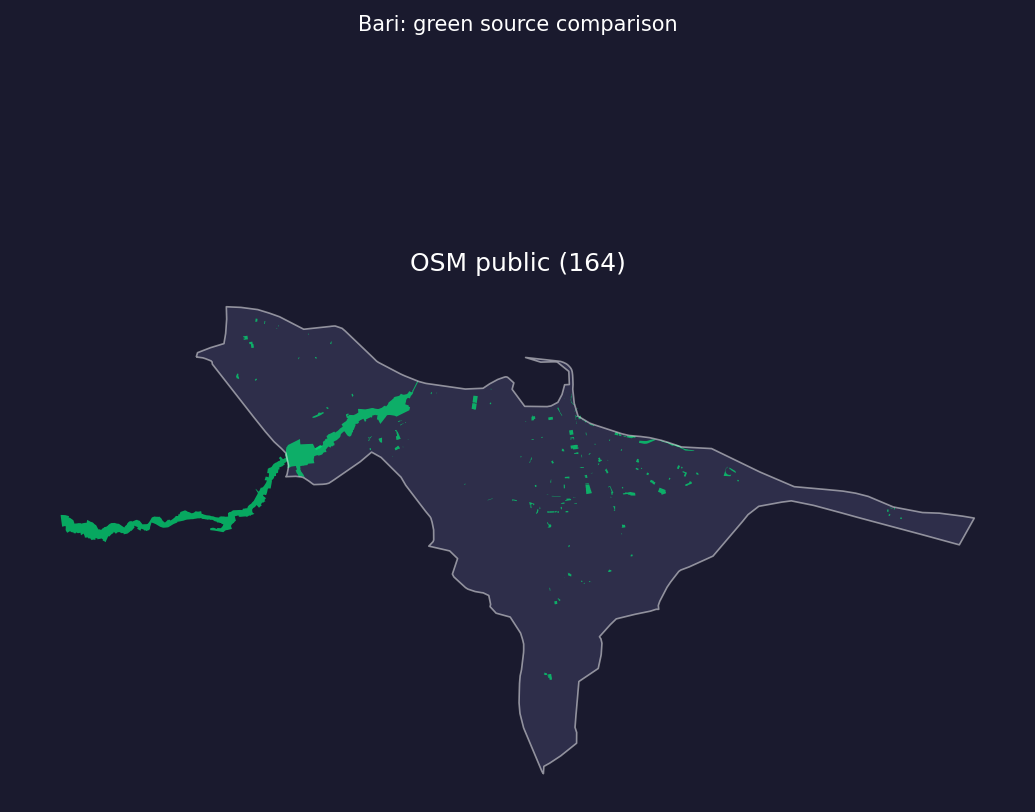

In [59]:
C_OSM   = "#00e676"
C_MUNI  = "#FFD54F"
C_SETT  = "#c44dff"
FIG_BG  = "#1a1a2e"
PAN_BG  = "#12122a"
LAND_BG = "#2e2e4a"

def _load_for_plot(table):
    exists = con.execute(f"""
        SELECT COUNT(*) FROM information_schema.tables
        WHERE table_schema = 'preprocessing' AND table_name = '{table}'
    """).fetchone()[0]
    if not exists:
        return None
    df = con.execute(f"""
        SELECT ST_AsWKB(geometry) AS geometry
        FROM preprocessing."{table}"
    """).df()
    df["geometry"] = df["geometry"].apply(bytes)
    
    return gpd.GeoDataFrame(
            geometry=gpd.array.from_wkb(df["geometry"]),
            crs=CRS_METRIC,
    )

osm_plot  = _load_for_plot(f"{CITY}_parks_osm")
muni_plot = _load_for_plot(f"{CITY}_parks_municipal")
pe_plot   = _load_for_plot(f"{CITY}_parks_dsbn_pe_unis")
ar_plot   = _load_for_plot(f"{CITY}_parks_dsbn_ar_vrd")

panels = []
if osm_plot  is not None: panels.append((osm_plot,  C_OSM,  f"OSM public ({len(osm_plot)})"))
if muni_plot is not None: panels.append((muni_plot, C_MUNI, f"Municipality ({len(muni_plot)})"))
if pe_plot   is not None: panels.append((pe_plot,   C_SETT, f"DBSN pe_unis ({len(pe_plot)})"))
if ar_plot   is not None: panels.append((ar_plot,   C_SETT, f"DBSN ar_vrd ({len(ar_plot)})"))

fig, axes = plt.subplots(1, len(panels), figsize=(7 * len(panels), 7), dpi=150)
if len(panels) == 1:
    axes = [axes]
fig.patch.set_facecolor(FIG_BG)

for ax, (gdf, color, title) in zip(axes, panels):
    ax.set_facecolor(PAN_BG)
    boundary_gdf.plot(ax=ax, color=LAND_BG, zorder=0)
    boundary_gdf.boundary.plot(ax=ax, color="white", linewidth=0.8, alpha=0.5, zorder=5)
    gdf.plot(ax=ax, color=color, alpha=0.7, zorder=3)
    ax.set_title(title, color="white", fontsize=12)
    ax.axis("off")

fig.suptitle(f"{CITY.title()}: green source comparison", color="white", fontsize=10)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig00_greenery_sources.png", dpi=150)

plt.show()

## 6. Deduplicate and merge
- `preprocessing.{CITY}_parks_greenery`

In [60]:
# Build UNION ALL only from layers that exist for this city
available_layers = []

layer_candidates = [
    f"{CITY}_parks_osm",
    f"{CITY}_parks_dsbn_pe_unis",
    f"{CITY}_parks_dsbn_ar_vrd",
    f"{CITY}_parks_municipal",
]

for tbl in layer_candidates:
    exists = con.execute(f"""
        SELECT COUNT(*) FROM information_schema.tables
        WHERE table_schema = 'preprocessing' AND table_name = '{tbl}'
    """).fetchone()[0]
    if exists:
        available_layers.append(tbl)

print(f"Merging layers: {available_layers}")

# just stack all sources, no dissolve, no dedup
union_sql = "\n    UNION ALL\n    ".join(
    f"SELECT geometry, '{t}' AS source FROM preprocessing.{t}" for t in available_layers
)

con.execute(f"""
    CREATE OR REPLACE TABLE preprocessing.{CITY}_parks_greenery AS
    SELECT
        row_number() OVER () AS park_id,
        '{CITY}'             AS city,
        source,
        ST_Area(geometry) / 1e4 AS area_ha,
        geometry
    FROM ({union_sql})
    WHERE ST_Area(geometry) >= 100
""")

result = con.execute(f"""
    SELECT COUNT(*) AS n, SUM(area_ha) AS total_ha
    FROM preprocessing.{CITY}_parks_greenery
""").fetchone()
print(f"Merged greenery: {result[0]:,} parks, {result[1]:.0f} ha total")

Merging layers: ['bari_parks_osm']
Merged greenery: 157 parks, 615 ha total


## 7. Sanity check

In [61]:
# Schema / table inventory
print("=== schemas ===")
print(con.execute("SELECT DISTINCT table_schema FROM information_schema.tables ORDER BY 1").df().to_string(index=False))

print("\n=== preprocessing tables ===")
tables = con.execute(f"""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'preprocessing'
      AND table_name LIKE '{CITY}%'
    ORDER BY table_name
""").df()["table_name"].tolist()

for t in tables:
    n = con.execute(f"SELECT COUNT(*) FROM preprocessing.{t}").fetchone()[0]
    print(f"  preprocessing.{t}: {n:,} rows")

=== schemas ===
 table_schema
preprocessing
   processing
          raw
    rule_300m

=== preprocessing tables ===
  preprocessing.bari_parks_greenery: 157 rows
  preprocessing.bari_parks_osm: 164 rows


In [62]:
# Round-trip geometry check: load one row and inspect bounds
check = con.execute(f"""
    SELECT
        COUNT(*)                             AS n,
        SUM(area_ha)                         AS total_ha,
        MIN(ST_XMin(geometry))               AS xmin,
        MAX(ST_XMax(geometry))               AS xmax
    FROM preprocessing.{CITY}_parks_greenery
""").fetchone()

print(f"Round-trip check: {check[0]:,} parks, {check[1]:.0f} ha")
print(f"X bounds (should be UTM metric, not ±180): {check[2]:.0f} … {check[3]:.0f}")

Round-trip check: 157 parks, 615 ha
X bounds (should be UTM metric, not ±180): 1143015 … 1172553


In [63]:
con.close()